[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/leehart3000/zarrextract/blob/main/notebooks/ome_zarr_idr0051.ipynb)

# Light-sheet microscopy (OME-Zarr) with zarrextract

This notebook reads small pieces of an OME-Zarr 0.5 image from the Image Data Resource (IDR): the intensity at one pixel over all 79 time points, and one 2D slice of the half-resolution image. The store is Zarr v3 and is read over HTTPS. Nothing is downloaded except the chunks that overlap each selection.

The image is a light-sheet movie of the neuromesodermal progenitor zone in the tailbud of a zebrafish embryo, with a nuclear marker. It has the dimensions t, c, z, y and x.

- Licence: CC BY 4.0. Copyright: Steventon et al.
- Study: IDR idr0051, "In Toto Cell Tracking using Lightsheet Microscopy of the Neuromesodermal Progenitor Zone of the Zebrafish Tailbud from the 21st Somite Stage". Data DOI: https://doi.org/10.17867/10000117
- Publication: Attardi A, Fulton T, Florescu M, Shah G, Muresan L, Lenz MO, Lancaster C, Huisken J, van Oudenaarden A, Steventon B (2018), Development, https://doi.org/10.1242/dev.166728
- Also cite the Image Data Resource: Williams E. et al. (2017), Nature Methods 14, 775-781, https://doi.org/10.1038/nmeth.4326

## Install

Reading a store over HTTPS needs `fsspec` and `aiohttp`. Colab already has both, so installing `zarrextract` is enough.

In [1]:
%pip install -q "zarrextract>=0.4.0"

In [2]:
import time
from datetime import UTC, datetime

import matplotlib.pyplot as plt
import numpy as np
import zarr

import zarrextract as zx

STORE = (
    "https://livingobjects.ebi.ac.uk/idr/zarr/v0.5/idr0051/"
    "180712_H2B_22ss_Courtney1_20180712-163837_p00_c00_preview.zarr"
)
FULL = "0/0"  # full resolution
HALF = "0/1"  # half resolution in y and x

accessed = datetime.now(UTC).strftime("%Y-%m-%d")
print(
    "Image Data Resource idr0051 (https://doi.org/10.17867/10000117), "
    "CC BY 4.0, Steventon et al., "
    f"accessed on {accessed}"
)

Image Data Resource idr0051 (https://doi.org/10.17867/10000117), CC BY 4.0, Steventon et al., accessed on 2026-11-27


## Look at the store

`zx.open()` opens the store once, and we use the same handle for everything below. `describe()` lists the arrays and the OME-Zarr groups without reading any data. This server cannot list folders, but the OME metadata names the image and its resolution levels, so `describe()` still finds them. Printing an entry of `description.ome` shows what it found.

In [3]:
src = zx.open(STORE)
description = src.describe()

for entry in description.ome:
    print(entry)
    print()

OME-Zarr bioformats2raw container '' (layout 3, version 0.5): 1 image, numbered: 0

OME-Zarr image '0' (version 0.5)
  multiscales 1 of 1 'Series 0'
    axes: t (time), c (channel), z (space), y (space), x (space)
    levels:
      0/0: shape (79, 1, 201, 333, 333), uint16, chunks (1, 1, 1, 333, 333)
        scale (1.0, 1.0, 1.0, 1.0, 1.0)
      0/1: shape (79, 1, 201, 166, 166), uint16, chunks (1, 1, 1, 333, 333)
        scale (1.0, 1.0, 1.0, 2.0, 2.0)
  channels: Channel 0
  labels: (none)



`extract()` takes the name of a level, as printed above: `0/0` is the full resolution and `0/1` is the half resolution in y and x. Each array has the dimensions t, c, z, y and x, the axes of the image.

## What the index positions mean

This store has no coordinate arrays for t, c, z, y and x, so zarrextract uses the index positions: `y=150` means the 151st row. The OME metadata says what the positions stand for. It lists the axes and, for each resolution level, the scale of each axis. `describe()` has already read it into the `OmeImage`.

In [4]:
image = description.images[0]
axes = image.multiscales[0].axes
names = [axis.name for axis in axes]

print("axes:")
for axis in axes:
    print(f"  {axis.name}: type {axis.type}, unit {axis.unit or 'not given'}")

scales = {}
print("scale of each axis, per resolution level:")
for level in image.levels:
    scales[level.path] = dict(zip(names, level.scale, strict=True))
    print(f"  {level.name}:", scales[level.path])

axes:
  t: type time, unit not given
  c: type channel, unit not given
  z: type space, unit not given
  y: type space, unit not given
  x: type space, unit not given
scale of each axis, per resolution level:
  0/0: {'t': 1.0, 'c': 1.0, 'z': 1.0, 'y': 1.0, 'x': 1.0}
  0/1: {'t': 1.0, 'c': 1.0, 'z': 1.0, 'y': 2.0, 'x': 2.0}


The scale of the full-resolution level is 1 on every axis and the axes have no unit. This image has no physical sizes in its metadata, so the positions are pixels and time points, and we cannot give them in micrometres or minutes. The half-resolution level has a scale of 2 in y and x: one of its pixels covers 2 full-resolution pixels. We use the scale to put the slice below in full-resolution pixels.

## A time series at one pixel

We pick the full-resolution pixel `y=150`, `x=100` in the middle plane `z=100` (of 201) and the only channel, `c=0`. It has signal: its intensity stays well above the background (a median near 160 in this plane) at every one of the 79 time points. A `(start, stop)` pair picks every value from start to stop, inclusive, so `t=(0, 78)` is the whole movie.

In [5]:
start = time.perf_counter()
series = src.extract(FULL, t=(0, 78), c=0, z=100, y=150, x=100)
elapsed = time.perf_counter() - start

print(f"{series.num_rows} rows in {elapsed:.1f} s")
print(series.slice(0, 3).to_pylist())

79 rows in 4.5 s
[{'t': 0, 'c': 0, 'z': 100, 'y': 150, 'x': 100, '0/0': 747}, {'t': 1, 'c': 0, 'z': 100, 'y': 150, 'x': 100, '0/0': 767}, {'t': 2, 'c': 0, 'z': 100, 'y': 150, 'x': 100, '0/0': 851}]


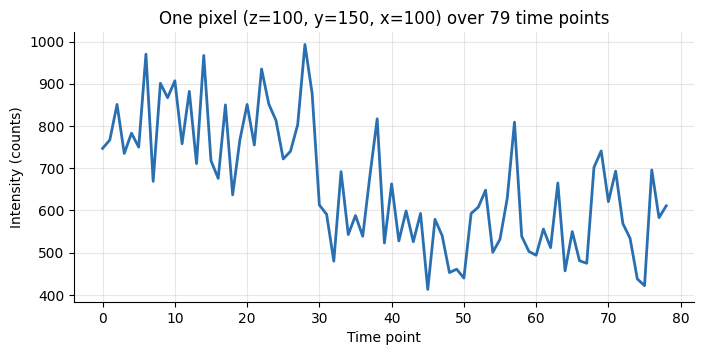

In [6]:
frames = series["t"].to_numpy()
intensity = series[FULL].to_numpy()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(frames, intensity, color="#2a6fb0", linewidth=2)
ax.set_xlabel("Time point")
ax.set_ylabel("Intensity (counts)")
ax.set_title("One pixel (z=100, y=150, x=100) over 79 time points")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## One 2D slice

A slice at `t=0`, `c=0` and the middle plane `z=100`, from the half-resolution level `0/1`. Leaving out `y` and `x` keeps them whole. The table has one row per pixel in C order (`x` changes fastest), so a reshape turns it back into an image.

In [7]:
start = time.perf_counter()
plane = src.extract(HALF, t=0, c=0, z=100)
elapsed = time.perf_counter() - start
print(f"{plane.num_rows} rows in {elapsed:.1f} s")

27556 rows in 0.2 s


The axes show full-resolution pixels: the scale of the level multiplies the index positions. The cross marks the pixel of the time series.

In [ ]:
n_y = np.unique(plane["y"].to_numpy()).size
n_x = np.unique(plane["x"].to_numpy()).size
plane_image = plane[HALF].to_numpy().reshape(n_y, n_x)

scale = scales["1"]
extent = (0, n_x * scale["x"], n_y * scale["y"], 0)  # left, right, bottom, top

fig, ax = plt.subplots(figsize=(6, 5.5))
shown = ax.imshow(plane_image, cmap="gray", extent=extent)
ax.plot(100 + 0.5, 150 + 0.5, marker="+", color="#e8a33d", markersize=14)
fig.colorbar(shown, ax=ax, label="Intensity (counts)")
ax.set_xlabel("x (full-resolution pixels)")
ax.set_ylabel("y (full-resolution pixels)")
ax.set_title("Time point 0, z=100, half resolution")
plt.show()

## Why this is cheap

zarrextract reads only the chunks the selection needs. That matters for light-sheet volumes, which are large: this array is split into shards of one whole volume (one time point), and each shard holds one chunk per z plane. The time series above needs one plane of each of the 79 time points. The cell below compares what that touches with the whole array.

In [9]:
group = zarr.open_group(STORE, mode="r")
array = group[FULL]
itemsize = array.dtype.itemsize
chunk_mb = np.prod(array.chunks) * itemsize / 1e6
whole_mb = np.prod(array.shape) * itemsize / 1e6

print("chunks:", array.chunks, "shards:", array.shards)
print(f"time series: 79 chunks of {chunk_mb:.2f} MB = {79 * chunk_mb:.0f} MB")
print(f"whole array: {whole_mb:,.0f} MB")

chunks: (1, 1, 1, 333, 333) shards: (1, 1, 201, 333, 333)
time series: 79 chunks of 0.22 MB = 18 MB
whole array: 3,522 MB


## Save the time series

`zx.write()` saves a table to a file, choosing the format from the suffix. Parquet keeps the provenance of the table in its schema. `zx.provenance()` reads it back from the file without reading the data.

In [10]:
from pathlib import Path

path = Path("series.parquet")
zx.write(series, path, overwrite=True)

info = zx.provenance(path)
print("store:", info.source)
print("variable:", info.variable)
print("selections:", info.selections)
print("zarrextract", info.version, "at", info.extracted_at)

store: https://livingobjects.ebi.ac.uk/idr/zarr/v0.5/idr0051/180712_H2B_22ss_Courtney1_20180712-163837_p00_c00_preview.zarr
variable: 0/0
selections: {'t': [0, 78], 'c': 0, 'z': 100, 'y': 150, 'x': 100}
zarrextract 0.4.0 at 2026-11-27 17:33:26+00:00
